# Transfer a pretrained normative model to your own site

*PCNtoolkit hands-on · Donders (f)MRI Toolkit 2026*

You collected scans at one site: here, the **ICBM** site of the open FCON1000 dataset (85 healthy adults, ages 19–85) and want to compute a Z-score for every person.

You have two options:

1. **Fit your own normative model** on your healthy controls.
2. **Transfer** a model that the PCN lab already trained on **67,000 people from 89 sites**.

We do both with the same 20 healthy controls (the adaptation set), and score the remaining 65 people (the test set) neither model has seen. To keep it simple we ignore sex at first.

[Open in Colab](https://colab.research.google.com/github/predictive-clinical-neuroscience/PCNtoolkit-demo-transfer/blob/main/notebooks/transfer_icbm.ipynb) · [PCNtoolkit docs](https://pcntoolkit.readthedocs.io/en/latest/)

## 1. Install PCNtoolkit
On Colab this takes about a minute.

In [ ]:
%pip install -q pcntoolkit==1.4.0

## 2. Imports

In [ ]:
import os
import warnings
import zipfile

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

import pcntoolkit.util.output
from pcntoolkit import (
    BLR,
    BsplineBasisFunction,
    NormativeModel,
    NormData,
    load_fcon1000,
    plot_centiles_advanced,
)

warnings.simplefilter("ignore")
pcntoolkit.util.output.Output.set_show_messages(False)

## 3. Download the pretrained 67K model

The PCN lab shares its pretrained models on [SURFdrive](https://surfdrive.surf.nl/s/Mb6mZyFmJeCaPcZ?dir=/zip). We use the cortical thickness model: Bayesian linear regression with a warp (`BLRw`), Destrieux atlas (`DES`), 67,000 people from 89 sites.

In [ ]:
MODEL_NAME = "BLRw_ct_DES_lifespan_67K_89sites"
BASE_URL = "https://surfdrive.surf.nl/public.php/webdav/zip/"
SHARE_TOKEN = "Mb6mZyFmJeCaPcZ"

os.makedirs("models", exist_ok=True)
zip_path = f"models/{MODEL_NAME}.zip"
model_dir = f"models/{MODEL_NAME}"

if not os.path.exists(zip_path):
    r = requests.get(BASE_URL + MODEL_NAME + ".zip", auth=(SHARE_TOKEN, ""), stream=True)
    r.raise_for_status()
    with open(zip_path, "wb") as f:
        for chunk in r.iter_content(chunk_size=1 << 20):
            f.write(chunk)
if not os.path.exists(model_dir):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(model_dir)

big_model = NormativeModel.load(model_dir)
print("covariates:", big_model.covariates)
print("batch effects:", list(big_model.unique_batch_effects))
print("brain measures:", len(big_model.response_vars))

covariates: ['age']
batch effects: ['site', 'sex']
brain measures: 150


## 4. Your data: the ICBM site

One row per person: age (covariate), site (batch effect), and the brain measure, with the same column name the pretrained model uses. The table also has sex; we leave it out of the models until section 10.

In [ ]:
REGION = "lh_G_precentral_thickness"

fcon = load_fcon1000().to_dataframe()
fcon.columns = [c[1] if isinstance(c, tuple) else c for c in fcon.columns]

icbm = fcon[fcon["site"] == "ICBM"][["site", "sex", "age", REGION]].dropna()
icbm["sub_id"] = icbm.index.astype(str)  # FCON1000 subject id
icbm = icbm.reset_index(drop=True)
print(f"{len(icbm)} people, ages {icbm.age.min():.0f}-{icbm.age.max():.0f}")
print(icbm.sex.value_counts().to_string())
icbm.head()

85 people, ages 19-85
sex
F    45
M    40


,site,sex,age,lh_G_precentral_thickness,sub_id
0,ICBM,M,25.0,2.474,580
1,ICBM,F,48.0,2.682,581
2,ICBM,M,26.0,1.978,582
3,ICBM,M,70.0,2.422,583
4,ICBM,F,19.0,2.456,584


## 5. Choose your adaptation and test subjects

We wrap the table in a `NormData` object and split it with PCNtoolkit's `train_test_split` function.

- **Adaptation set** (`adaptation`): healthy controls used to fit your own model, or to transfer the 67K model. `splits=(0.24, 0.76)` gives 20 of the 85.
- **Test set** (`test`): the other 65, whom neither model has seen. We run the evaluation metrics on them to see the quality of the fit or transfer.

In [ ]:
import copy

# PCNtoolkit accepts NormData objects
icbm_data = NormData.from_dataframe(
        "icbm", icbm, covariates=["age"], batch_effects=["site"],
        response_vars=[REGION], subject_ids="sub_id",
    )
# Split your data
adaptation, test = icbm_data.train_test_split(splits=(0.24, 0.76), random_state=5)
print(f"adaptation: {adaptation.X.shape[0]}   test: {test.X.shape[0]}")

adaptation: 20   test: 65


## 6. Option 1: fit your own model

We fit a warped Bayesian linear regression. `fixed_effect=True` lets the model learn a separate offset for each batch effect; with one site and no sex that does nothing yet, but it matters in section 10.

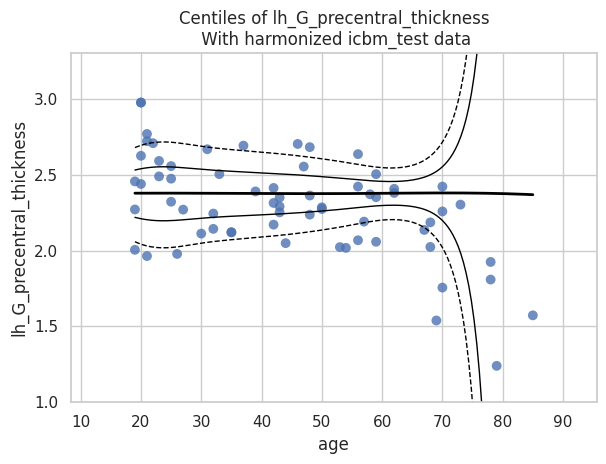

In [ ]:
# create wBLR model
own_template = BLR(
    name="own",
    heteroskedastic=True,
    fixed_effect=True,
    warp_name="WarpSinhArcsinh",
    basis_function_mean=BsplineBasisFunction(basis_column=0, nknots=5, degree=3),
    basis_function_var=BsplineBasisFunction(basis_column=0, nknots=5, degree=3),
)
own_model = NormativeModel(
    template_regression_model=own_template,
    inscaler="standardize", outscaler="standardize",
    savemodel=False, saveresults=False, saveplots=False, evaluate_model=True,
    save_dir="results/own",
)

# fit
own_test = own_model.fit_predict(adaptation, copy.deepcopy(test))

# plot
plot_centiles_advanced(own_model, scatter_data=own_test, show_legend=False,
                       show_figure=False, show_centile_labels=False)
# limit the y axis so that the plot does not blow up
plt.ylim(1.0, 3.3)
plt.show()

## 7. Option 2: transfer the 67K model

Transfer keeps the age curve the big model learned from 67,000 people and only learns, from your controls, how much your site is shifted and how wide it scatters.

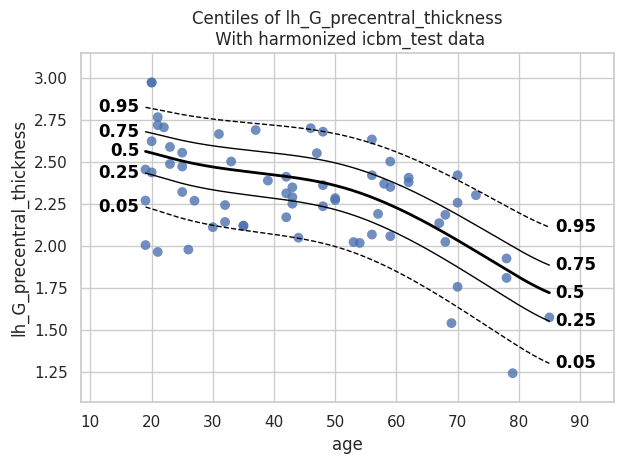

In [ ]:
tr_test = copy.deepcopy(test)

# transfer
transferred_model = big_model.transfer_predict(adaptation, tr_test, save_dir="results/transfer")

# plot
plot_centiles_advanced(transferred_model, scatter_data=tr_test, show_legend=False);

## 8. Compare on the people neither model has seen

Two checks of the Z-score **distribution** of healthy people:

- **outside |Z| > 2**: should be about 5%.
- **MACE** (mean absolute centile error): for the 5th, 25th, 50th, 75th and 95th centile, how far the share of people below that centile is from what it should be. 0 is perfect.

In [ ]:
def scores(data):
    z = data.Z.sel(response_vars=REGION).values
    return {
        "outside |Z|>2 (%)": round(float(np.mean(np.abs(z) > 2) * 100), 1),
        "MACE": round(float(data.statistics.sel(response_vars=REGION, statistic="MACE")), 3),
    }

pd.DataFrame({"fit on my site only": scores(own_test), "67K transfer": scores(tr_test)})

,fit on my site only,67K transfer
outside |Z|>2 (%),24.600,10.800
MACE,0.077,0.048


## 9. Your turn

- Change `splits` in section 5, e.g. `(0.12, 0.88)` for 10 controls or `(0.71, 0.29)` for 60, and run everything from there again. How does that affect your transfer and fit?
- Change `random_state` to get a different set of controls. Which model changes more?
- Change `REGION` to another thickness column, e.g. `rh_G_precentral_thickness`.

The [web app](https://predictive-clinical-neuroscience.github.io/PCNtoolkit-demo-transfer/) shows all of these, precomputed.

**Your own data:** replace `icbm` with your table (same column names as the model; sex coded `F`/`M` if you model it), keep healthy controls for transfer, and score everyone else, including patients. No Python? [PCNportal](https://pcnportal.dccn.nl/) does the same transfer in the browser.

## 10. Next step: add sex back

So far both models ignore sex. Usually men and women have different thicknesses and we need to take that into account in our model.

- Rerun the analysis with sex as a second batch effect: `batch_effects=("site", "sex")`. How does that change your fit and your transfer, are they as accurate as before? Is there a difference in the thickness of the left precentral gyrus in men vs women?
- How does `plot_centiles_advanced` show two sexes in one plot? Hint: `plot_centiles_advanced` uses **harmonisation**. You can read more in the [PCNtoolkit docs](https://pcntoolkit.readthedocs.io/en/stable/tutorials/02_BLR.html#harmonize).

Questions: [NeuroStars](https://neurostars.org/tag/pcntoolkit) · [GitHub issues](https://github.com/predictive-clinical-neuroscience/PCNtoolkit/issues)